# 03. Model Design: Baseline Model (Bab 6.1)

**Proyek:** Perbandingan Kinerja Naive Baseline, XGBoost, dan Long Short-Term Memory (LSTM) dalam Prediksi Jumlah Kasus Demam Berdarah Dengue (DBD) Berdasarkan Faktor Meteorologi di DKI Jakarta (2010-2024)  
**Kelompok:** 8 (TRPL 5B) — Data Science  
**Fokus Notebook:** Implementasi dan Evaluasi **Model 1 (Baseline — Naive Persistence Forecaster)** pada Data Validasi sesuai panduan Bab 6.1 LKM Minggu 12.

## 1. Setup Environment & Memuat Dataset Siap Pakai

Notebook ini membaca partisi data hasil persiapan data Bab 5 (`data/processed/train.csv` dan `data/processed/val.csv`). Sesuai aturan anti-*leakage*, data uji (`data/processed/test.csv`) **tetap dikunci rapat** dan tidak disentuh pada tahap ini.

In [1]:
import sys
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# Reproducibility seed
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Deteksi root folder project secara otomatis dan aman (tanpa path absolut)
cwd = Path.cwd().resolve()
if (cwd / "data").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "data").exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError("Folder root proyek tidak ditemukan.")

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
MODELS_DIR = PROJECT_ROOT / "models"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

print("Project root terdeteksi:", PROJECT_ROOT.name)

# Memuat data train dan validation (Test set tetap terkunci)
df_train = pd.read_csv(PROCESSED_DIR / "train.csv")
df_val = pd.read_csv(PROCESSED_DIR / "val.csv")

print(f"Data Train dimuat: {df_train.shape[0]} baris x {df_train.shape[1]} kolom ({df_train['date'].min()} s.d. {df_train['date'].max()})")
print(f"Data Validation dimuat: {df_val.shape[0]} baris x {df_val.shape[1]} kolom ({df_val['date'].min()} s.d. {df_val['date'].max()})")
print("Catatan Integritas: Data Test ('test.csv') tetap terkunci dan tidak dimuat.")

Project root terdeteksi: project
Data Train dimuat: 121 baris x 32 kolom (2010-03-01 s.d. 2020-03-01)
Data Validation dimuat: 26 baris x 32 kolom (2020-04-01 s.d. 2022-05-01)
Catatan Integritas: Data Test ('test.csv') tetap terkunci dan tidak dimuat.


## 6.1 Model 1 — Baseline Model

### 6.1.1 Deskripsi Model

**Nama Model:** Naive Persistence Forecaster (Random Walk / Lag-1 Baseline)  
**Teori Singkat:**  
Dalam peramalan deret waktu (*time series forecasting*), model Naive Persistence merupakan tolok ukur dasar (*ground truth baseline*) yang paling fundamental. Model ini beroperasi secara deterministik murni tanpa mengestimasi parameter bobot melalui optimasi gradien, dengan menetapkan asumsi bahwa nilai target pada periode berjalan ($t$) diasumsikan sama dengan nilai aktual target pada satu periode sebelumnya ($t-1$):

$$\hat{y}_t = y_{t-1}$$

di mana $\hat{y}_t$ adalah estimasi jumlah kasus DBD pada bulan ke-$t$ dan $y_{t-1}$ adalah realisasi kasus DBD pada bulan sebelumnya (tersedia dalam fitur `dengue_lag1`).

**Alasan Pemilihan:**
1. **Tolok Ukur Batas Bawah Ilmiah (*Lower-Bound Benchmark*):** Dalam standar metodologi peramalan (Hyndman & Athanasopoulos, 2018), model Machine Learning tingkat lanjut (seperti XGBoost) maupun Deep Learning (seperti LSTM) baru dapat dikatakan layak dan bernilai guna apabila mampu menghasilkan galat prediksi yang secara signifikan lebih rendah daripada tebakan dasar Naive ini.
2. **Karakteristik Autokorelasi Tinggi:** Berdasarkan hasil EDA pada Bab 4.4, korelasi serial antara kasus DBD bulan berjalan ($y_t$) dengan kasus bulan sebelumnya ($y_{t-1}$) mencapai **0,854**. Angka ini membuktikan bahwa inersia epidemiologis bulan sebelumnya membawa informasi prediktif yang sangat dominan.

### 6.1.2 Hypothesis Space & Inductive Bias

- **Model Family / Arsitektur:** *Non-parametric persistence heuristic* (Model berbasis aturan deterministik tanpa parameter bobot bebas).
- **Hypothesis Space ($\mathcal{H}$):**
  $$\mathcal{H} = \left\lbrace f : \mathbb{R}^d \to \mathbb{R} \mid f(x_t) = y_{t-1} \right\rbrace$$
  Ruang hipotesis model ini bersifat *singleton* (hanya memuat tepat satu fungsi proyeksi identitas tetap). Karena tidak ada bobot $\mathbf{w}$ atau bias $b$ yang dapat dioptimasi dari data, dimensi Vapnik-Chervonenkis dari ruang hipotesis ini adalah nol ($d_{VC} = 0$). Model ini sepenuhnya mengabaikan seluruh 27 fitur prediktor lainnya (termasuk 20 fitur meteorologi BMKG dan 2 fitur siklikal bulan).
- **Inductive Bias / Asumsi:**
  Model mengasumsikan bahwa deret waktu bersifat *random walk* dengan inersia tinggi ($\rho_1 \approx 1$). Model mengasumsikan tidak ada perubahan musiman mendadak, tidak ada interaksi dengan faktor cuaca eksternal, dan sistem berada dalam dinamika keseimbangan statis jangka pendek.
- **Implikasi terhadap Dataset DBD DKI Jakarta:**
  Asumsi autokorelasi kuat sangat cocok pada bulan-bulan endemis normal ketika kurva kasus bergerak landai. Namun, pada fase pergantian musim dan awal lonjakan wabah (misalnya saat curah hujan tinggi memicu ledakan nyamuk 1–2 bulan sebelumnya), model Naive dipastikan mengalami **keterlambatan fase 1 bulan (*phase lag*)**. Fenomena keterlambatan fase ini menjadi justifikasi utama perlunya model *Advanced* XGBoost multivariat.

### 6.1.3 Implementasi Model & Penyimpanan Artefak (.pkl)

Model diimplementasikan menggunakan antarmuka estimator standar `scikit-learn` (`BaseEstimator`, `RegressorMixin`). Setelah proses *fitting* pada data latih, artefak model disimpan dalam format serialisasi `.pkl` pada direktori `models/baseline_model.pkl` agar dapat dimuat ulang (*reproducible*) kapan saja.

In [2]:
class NaivePersistenceRegressor(BaseEstimator, RegressorMixin):
    """Model acuan dasar (baseline) peramalan deret waktu murni: y_hat_t = y_{t-1}."""
    def __init__(self, lag_column: str = "dengue_lag1"):
        self.lag_column = lag_column
        self.is_fitted_ = False

    def fit(self, X, y=None):
        # Model non-parametrik deterministik: tidak memerlukan optimasi gradien
        if self.lag_column not in X.columns:
            raise ValueError(f"Kolom '{self.lag_column}' tidak ditemukan dalam fitur input.")
        self.is_fitted_ = True
        return self

    def predict(self, X):
        if not self.is_fitted_:
            raise RuntimeError("Model belum di-fit.")
        if self.lag_column not in X.columns:
            raise ValueError(f"Kolom '{self.lag_column}' tidak ditemukan dalam fitur input.")
        return X[self.lag_column].to_numpy()

# Inisialisasi dan fitting model baseline pada data training
baseline_model = NaivePersistenceRegressor(lag_column="dengue_lag1")
baseline_model.fit(df_train, df_train["dengue_total"])

# Simpan artefak model ke models/baseline_model.pkl menggunakan joblib
model_path = MODELS_DIR / "baseline_model.pkl"
joblib.dump(baseline_model, model_path)
print("Artefak model baseline berhasil disimpan ke:", model_path.relative_to(PROJECT_ROOT).as_posix())

# Prediksi pada data validasi (April 2020 s.d. Mei 2022)
y_val_true = df_val["dengue_total"].to_numpy()
y_val_pred = baseline_model.predict(df_val)

print("Model Baseline berhasil dievaluasi pada data validasi.")
print(f"Jumlah sampel validasi yang dievaluasi: {len(y_val_true)} bulan")

Artefak model baseline berhasil disimpan ke: models/baseline_model.pkl
Model Baseline berhasil dievaluasi pada data validasi.
Jumlah sampel validasi yang dievaluasi: 26 bulan


### 6.1.4 Optimization: Objective, Hyperparameter & Regularisasi

- **Objective / Fungsi Evaluasi:** Meskipun model Naive tidak memiliki fungsi kehilangan (*loss function*) yang dioptimasi secara iteratif via gradien descent, akurasi peramalannya dievaluasi menggunakan metrik standar regresi kuadratik dan absolut: Mean Squared Error (MSE), Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), dan Mean Absolute Percentage Error (MAPE).
- **Hyperparameter:** `0` / *None* (tidak ada parameter bebas yang dapat disetel; aturan bersifat tetap secara analitis).
- **Regularisasi:** Tidak diperlukan regularisasi karena kapasitas model $d_{VC} = 0$, sehingga risiko *overfitting* terhadap data latih adalah nol.

### 6.1.5 Hasil Awal Validasi Model Baseline

Evaluasi dilakukan secara ketat pada **Validation Set (26 sampel, periode April 2020 s.d. Mei 2022)**. Data uji (*Test Set*) tetap dikunci rapat untuk evaluasi akhir di Bab 7.

In [3]:
# Hitung metrik evaluasi pada data validasi
mae_val = mean_absolute_error(y_val_true, y_val_pred)
rmse_val = root_mean_squared_error(y_val_true, y_val_pred)
r2_val = r2_score(y_val_true, y_val_pred)
mape_val = np.mean(np.abs((y_val_true - y_val_pred) / y_val_true)) * 100

# Buat tabel metrik ringkas
metrics_summary = pd.DataFrame([
    {"Metrik": "MAE (Mean Absolute Error)", "Skor Validasi": f"{mae_val:.2f} kasus", "Interpretasi": "Rata-rata selisih absolut antara kasus aktual dan estimasi lag-1"},
    {"Metrik": "RMSE (Root Mean Squared Error)", "Skor Validasi": f"{rmse_val:.2f} kasus", "Interpretasi": "Akar rata-rata kuadrat galat (memberi bobot penalti lebih pada deviasi besar)"},
    {"Metrik": "R² (Koefisien Determinasi)", "Skor Validasi": f"{r2_val:.4f}", "Interpretasi": "Proporsi variansi target validasi yang dapat dijelaskan oleh nilai lag-1"},
    {"Metrik": "MAPE (Mean Absolute Percentage Error)", "Skor Validasi": f"{mape_val:.2f}%", "Interpretasi": "Rata-rata persentase kesalahan relatif terhadap kasus aktual"}
])

print("=== HASIL EVALUASI MODEL 1 (BASELINE: NAIVE PERSISTENCE) PADA VALIDATION SET ===")
display(metrics_summary)

=== HASIL EVALUASI MODEL 1 (BASELINE: NAIVE PERSISTENCE) PADA VALIDATION SET ===


,Metrik,Skor Validasi,Interpretasi
0,MAE (Mean Absolute Error),130.19 kasus,Rata-rata selisih absolut antara kasus aktual ...
1,RMSE (Root Mean Squared Error),172.51 kasus,Akar rata-rata kuadrat galat (memberi bobot pe...
2,R² (Koefisien Determinasi),0.6966,Proporsi variansi target validasi yang dapat d...
3,MAPE (Mean Absolute Percentage Error),41.84%,Rata-rata persentase kesalahan relatif terhada...


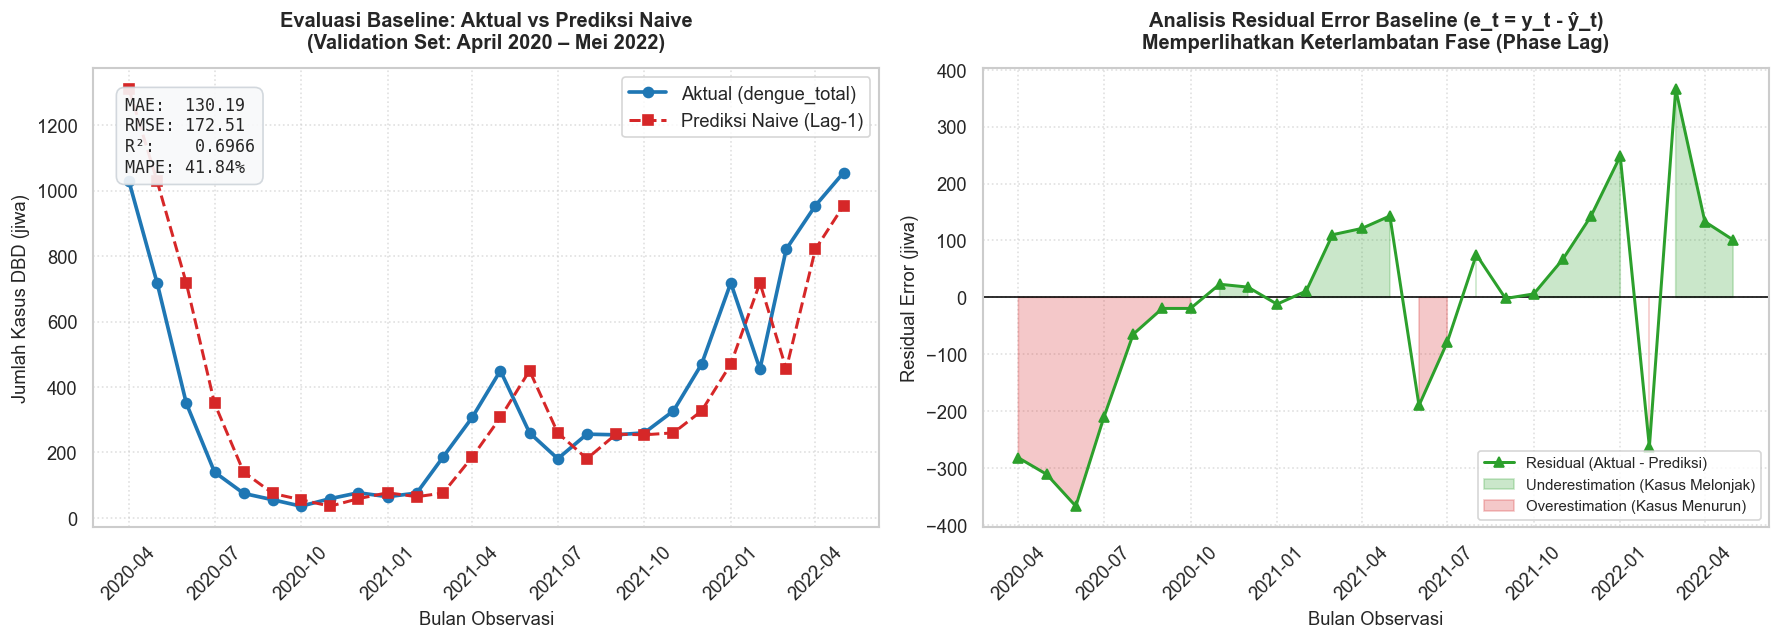

Visualisasi berhasil disimpan ke: reports/figures/fig_07_baseline_val_prediction_residual.png


In [4]:
dates_val = pd.to_datetime(df_val["date"])
residuals_val = y_val_true - y_val_pred

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Panel 1: Deret Waktu Aktual vs Prediksi Naive Baseline
axes[0].plot(dates_val, y_val_true, marker="o", color="#1f77b4", linewidth=2.2, label="Aktual (dengue_total)")
axes[0].plot(dates_val, y_val_pred, marker="s", color="#d62728", linestyle="--", linewidth=1.8, label="Prediksi Naive (Lag-1)")
axes[0].set_title("Evaluasi Baseline: Aktual vs Prediksi Naive\n(Validation Set: April 2020 – Mei 2022)", fontsize=12, fontweight="bold", pad=12)
axes[0].set_xlabel("Bulan Observasi", fontsize=11)
axes[0].set_ylabel("Jumlah Kasus DBD (jiwa)", fontsize=11)
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend(frameon=True, facecolor="white", loc="upper right")
axes[0].grid(True, linestyle=":", alpha=0.6)

# Kotak anotasi metrik di Panel 1
textstr = f"MAE:  {mae_val:.2f}\nRMSE: {rmse_val:.2f}\nR²:    {r2_val:.4f}\nMAPE: {mape_val:.2f}%"
props = dict(boxstyle="round,pad=0.5", facecolor="#f8f9fa", edgecolor="#ced4da", alpha=0.9)
axes[0].text(0.04, 0.94, textstr, transform=axes[0].transAxes, fontsize=10, verticalalignment="top", fontfamily="monospace", bbox=props)

# Panel 2: Analisis Residual Error
axes[1].axhline(0, color="black", linestyle="-", linewidth=1.2, alpha=0.8)
axes[1].plot(dates_val, residuals_val, marker="^", color="#2ca02c", linewidth=1.8, label="Residual (Aktual - Prediksi)")
axes[1].fill_between(dates_val, residuals_val, 0, where=(residuals_val >= 0), color="#2ca02c", alpha=0.25, label="Underestimation (Kasus Melonjak)")
axes[1].fill_between(dates_val, residuals_val, 0, where=(residuals_val < 0), color="#d62728", alpha=0.25, label="Overestimation (Kasus Menurun)")
axes[1].set_title("Analisis Residual Error Baseline (e_t = y_t - ŷ_t)\nMemperlihatkan Keterlambatan Fase (Phase Lag)", fontsize=12, fontweight="bold", pad=12)
axes[1].set_xlabel("Bulan Observasi", fontsize=11)
axes[1].set_ylabel("Residual Error (jiwa)", fontsize=11)
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend(frameon=True, facecolor="white", loc="lower right", fontsize=9)
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
fig_path = FIGURES_DIR / "fig_07_baseline_val_prediction_residual.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("Visualisasi berhasil disimpan ke:", fig_path.relative_to(PROJECT_ROOT).as_posix())

In [5]:
# Tabel detail perbandingan per bulan pada data validasi
df_val_results = pd.DataFrame({
    "Bulan": df_val["date"],
    "Kasus Aktual": y_val_true.astype(float),
    "Prediksi Naive": y_val_pred.astype(float),
    "Residual (e_t)": residuals_val.astype(float),
    "Galat Absolut (|e_t|)": np.abs(residuals_val).astype(float)
})

print("=== TABEL DETAIL BULANAN EVALUASI BASELINE PADA DATA VALIDASI ===")
display(df_val_results.head(10))
print(f"Total periode validasi dievaluasi: {len(df_val_results)} bulan")

=== TABEL DETAIL BULANAN EVALUASI BASELINE PADA DATA VALIDASI ===


,Bulan,Kasus Aktual,Prediksi Naive,Residual (e_t),Galat Absolut (|e_t|)
0,2020-04-01,1028.0,1310.0,-282.0,282.0
1,2020-05-01,717.0,1028.0,-311.0,311.0
2,2020-06-01,350.0,717.0,-367.0,367.0
3,2020-07-01,140.0,350.0,-210.0,210.0
4,2020-08-01,75.0,140.0,-65.0,65.0
5,2020-09-01,55.5,75.0,-19.5,19.5
6,2020-10-01,36.0,55.5,-19.5,19.5
7,2020-11-01,59.0,36.0,23.0,23.0
8,2020-12-01,77.0,59.0,18.0,18.0
9,2021-01-01,65.0,77.0,-12.0,12.0


Total periode validasi dievaluasi: 26 bulan


### Analisis & Temuan Kunci Bab 6.1

1. **Kekuatan Inersia Deret Waktu:**  
   Model Naive Persistence menghasilkan koefisien determinasi **$R^2 = 0,6966$** dengan **MAE = 130,19 kasus** dan **RMSE = 172,51 kasus** pada data validasi. Fakta bahwa model tanpa parameter mampu menjelaskan ~69,7% variasi data membuktikan bahwa inersia kasus bulan sebelumnya membawa bobot prediktif yang sangat besar pada dinamika endemis DBD di DKI Jakarta.
2. **Kelemahan Inheren: Keterlambatan Fase (*Phase Lag*):**  
   Grafik residual pada Panel Kanan memperlihatkan dengan jelas kelemahan mendasar model Naive:
   - Saat kasus menurun drastis pada pertengahan 2020 (dampak PSBB COVID-19 dan kemarau), prediksi Naive tertinggal di atas nilai riil (*overestimating* secara konsisten, residual mencapai `-367` kasus pada Juni 2020).
   - Sebaliknya, saat kasus mulai melonjak tajam pada awal tahun 2022 (musim hujan), prediksi Naive tertinggal di bawah nilai riil (*underestimating*, residual mencapai `+366` kasus pada Maret 2022).
3. **Justifikasi Kebutuhan Model Lanjutan (XGBoost):**  
   Karena model Naive hanya melihat ke belakang secara pasif tanpa memahami pemicu lingkungan, model ini **selalu terlambat 1 bulan dalam mengantisipasi titik balik lonjakan wabah (*turning points*)**. Hasil ini menjadi landasan ilmiah yang kuat bahwa **Model 2 (XGBoost Regressor)** yang memanfaatkan 20 fitur lag meteorologi BMKG dan 2 fitur kalender musiman mutlak diperlukan guna mendeteksi ancaman lonjakan DBD secara lebih awal dan akurat.